<a href="https://colab.research.google.com/github/22F3000107/22F3000107/blob/main/Way2Agribusiness_Price_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Way2Agribusiness India Pvt Ltd — Monthly Price Forecasting
**Internship assignment | Django, FastAPI and AI/ML**

**Candidate:** Deepak Kumar  
**Contact number:** *8227953824*  
**Email ID:** *deepakjaykar302@gmail.com*

## Objective
Use the supplied historical monthly price dataset to clean and explore the data, evaluate a forecasting model using a time-ordered holdout, forecast the next 12 months after the last observed month, recommend business actions, and outline a production deployment using Django, FastAPI, Next.js and React Native.

> **Data freshness note:** The supplied dataset ends in September 2025. Therefore, the 12-month forecast in this notebook is for **October 2025–September 2026**, relative to the last observation. It is not a current forecast from October 2026. For operational use, obtain updated data and retrain the model.

## 1. Imports and reproducibility
The notebook uses pandas/numpy for data handling, Matplotlib for plots, and statsmodels for Holt's damped-trend exponential smoothing. A simple last-value baseline is evaluated alongside the selected model.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

RANDOM_SEED = 42
# In Colab, upload the supplied CSV when it is not already available.
from pathlib import Path
DATA_PATH = Path("/content/price_data.csv")
if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("Upload the original assignment CSV (must contain date and avg_monthly_price).")
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("No CSV was uploaded.")
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if len(csv_names) != 1:
            raise ValueError("Upload exactly one CSV, then rerun this cell.")
        DATA_PATH = Path(csv_names[0])
    except ImportError:
        raise FileNotFoundError("Place price_data.csv in /content/ or set DATA_PATH to your CSV location.")
print("Dataset:", DATA_PATH)

Upload the original assignment CSV (must contain date and avg_monthly_price).


Saving price_data.csv to price_data (1).csv
Dataset: price_data (1).csv


## 2. Load and inspect the data

In [ ]:
df = pd.read_csv(DATA_PATH)
required_columns = {"date", "avg_monthly_price"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["avg_monthly_price"] = pd.to_numeric(df["avg_monthly_price"], errors="coerce")
print("Rows and columns:", df.shape)
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))
display(df.head())
display(df.tail())

Rows and columns: (249, 2)
Data types:


,dtype
date,datetime64[ns]
avg_monthly_price,int64


Missing values:


,missing_count
date,0
avg_monthly_price,0


,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876


,date,avg_monthly_price
244,2025-05-01,14263
245,2025-06-01,14263
246,2025-07-01,16000
247,2025-08-01,15025
248,2025-09-01,15750


## 3. Data cleaning and quality checks

Cleaning decisions are deliberately conservative because this is a time series: do not remove a high or low price solely because it is unusual. Such observations may reflect real market conditions. We remove rows with invalid dates/prices, sort chronologically, resolve duplicate months using the monthly median, and create a complete month-start index. Any missing monthly observations are time-interpolated for model fitting and are flagged for review. Outliers are flagged using the IQR rule, not automatically deleted.

In [ ]:
initial_rows = len(df)
df = df.dropna(subset=["date", "avg_monthly_price"]).copy()
df = df[df["avg_monthly_price"] > 0].copy()
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()
duplicate_months = int(df["month"].duplicated(keep=False).sum())

# If multiple records exist for a month, aggregate them robustly using the median.
monthly = df.groupby("month")["avg_monthly_price"].median().sort_index()
monthly.index = pd.DatetimeIndex(monthly.index, name="date")
monthly = monthly.asfreq("MS")

missing_months = monthly[monthly.isna()].index
missing_month_count = int(monthly.isna().sum())
if missing_month_count:
    monthly = monthly.interpolate(method="time", limit_direction="both")

q1, q3 = monthly.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_flags = (monthly < lower_bound) | (monthly > upper_bound)

print(f"Rows before cleaning: {initial_rows}")
print(f"Rows after invalid date/price removal: {len(df)}")
print(f"Rows involved in duplicate months (before aggregation): {duplicate_months}")
print(f"Missing months inserted into regular monthly index: {missing_month_count}")
print(f"IQR outlier flags: {int(outlier_flags.sum())}")
print(f"IQR bounds: {lower_bound:.2f} to {upper_bound:.2f}")
print("Decision: retain flagged prices unless source validation shows a data-entry error.")
display(pd.DataFrame({"price": monthly, "iqr_outlier_flag": outlier_flags}).loc[outlier_flags])

Rows before cleaning: 249
Rows after invalid date/price removal: 249
Rows involved in duplicate months (before aggregation): 0
Missing months inserted into regular monthly index: 0
IQR outlier flags: 7
IQR bounds: 633.00 to 15273.00
Decision: retain flagged prices unless source validation shows a data-entry error.


,price,iqr_outlier_flag
date,,
2023-12-01,16163.0,True
2024-04-01,15863.0,True
2024-05-01,15863.0,True
2024-06-01,15488.0,True
2024-07-01,15294.0,True
2025-07-01,16000.0,True
2025-09-01,15750.0,True


## 4. Exploratory analysis

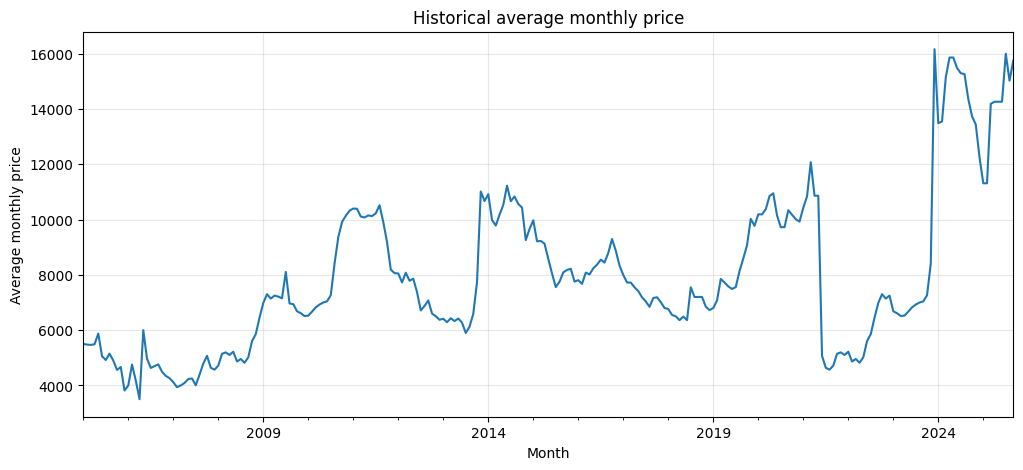

Start: 2005-01-01
End: 2025-09-01
Number of monthly observations: 249


,summary
count,249.000000
mean,7918.891566
std,2804.992684
min,3500.000000
25%,6123.000000
50%,7250.000000
75%,9783.000000
max,16163.000000


In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
monthly.plot(ax=ax, title="Historical average monthly price")
ax.set_xlabel("Month")
ax.set_ylabel("Average monthly price")
ax.grid(True, alpha=0.3)
plt.show()

print("Start:", monthly.index.min().date())
print("End:", monthly.index.max().date())
print("Number of monthly observations:", len(monthly))
display(monthly.describe().to_frame("summary"))

### Additional EDA: year-over-year changes and monthly seasonality
These are descriptive charts only. They do not prove a stable seasonal forecasting pattern.

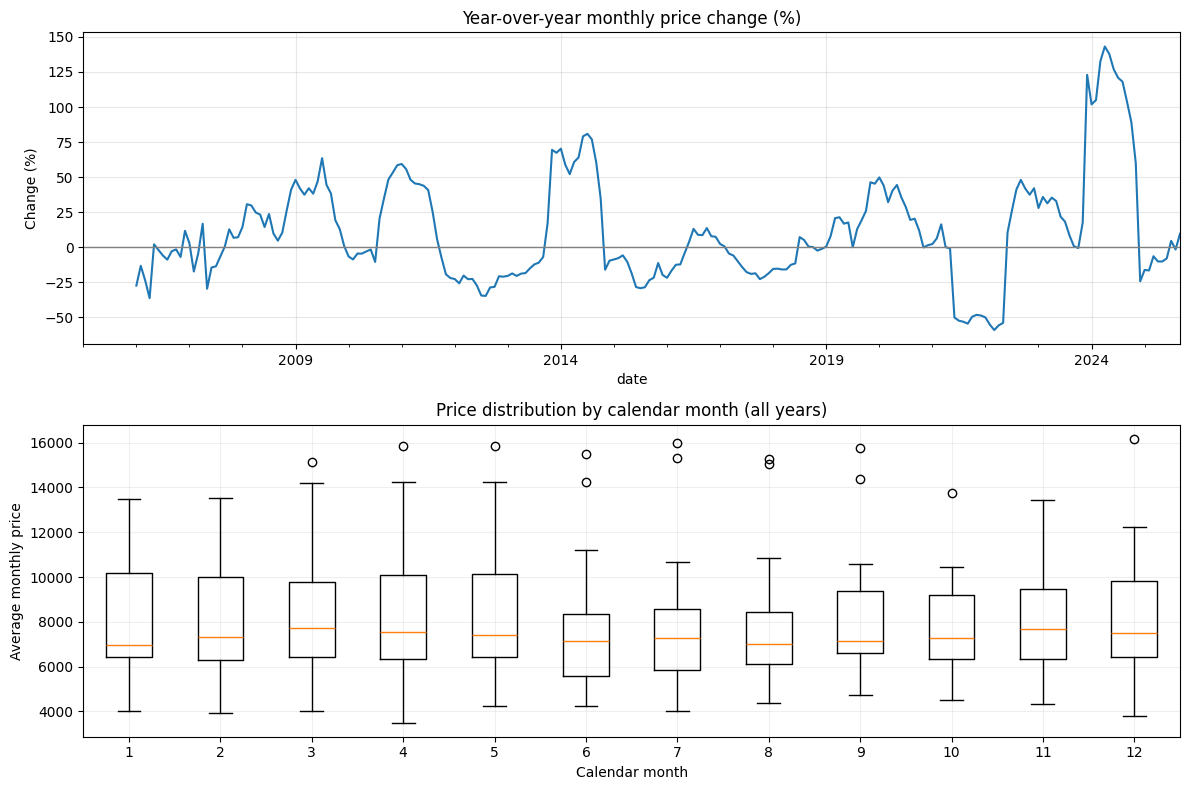

Year-over-year change summary (%):


,value
count,237.00
mean,11.10
std,37.67
min,-58.96
25%,-14.98
50%,2.33
75%,32.98
max,143.11


In [ ]:
# Avoid interpreting seasonal patterns without checking multiple years.
eda = monthly.rename("price").to_frame()
eda["year"] = eda.index.year
eda["calendar_month"] = eda.index.month
eda["yoy_change_pct"] = eda["price"].pct_change(12) * 100

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
eda["yoy_change_pct"].plot(ax=axes[0], title="Year-over-year monthly price change (%)")
axes[0].axhline(0, linewidth=1, color="gray")
axes[0].set_ylabel("Change (%)")
axes[0].grid(alpha=0.3)

monthly_box = [eda.loc[eda["calendar_month"] == m, "price"].dropna().values
               for m in range(1, 13)]
axes[1].boxplot(monthly_box, labels=list(range(1, 13)))
axes[1].set_title("Price distribution by calendar month (all years)")
axes[1].set_xlabel("Calendar month")
axes[1].set_ylabel("Average monthly price")
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Year-over-year change summary (%):")
display(eda["yoy_change_pct"].describe().to_frame("value").round(2))

## 5. Model choice and evaluation design

**Selected candidate:** Holt's linear exponential smoothing with a damped additive trend and no explicit seasonal component.

Reasons:
- The dataset is a univariate monthly series with a long-term level/trend and a relatively short recent history at the end.
- Holt's method can model a changing level and trend without requiring external explanatory variables.
- Damping limits unrealistic indefinite extrapolation of the recent trend.
- A seasonal model is not assumed without evidence that a stable 12-month seasonal pattern exists.

**Evaluation:** Reserve the final 12 observed months as a test set. Train on all earlier observations, forecast those 12 months, and compare against a last-observation (naive) baseline. This is a chronological split, not a random split. With only one holdout window, metrics are indicative rather than definitive; rolling-origin backtesting would be a useful next step.

,MAE,RMSE,MAPE (%)
Naive baseline,1160.33,1565.74,9.12
Seasonal naive,2296.42,2921.06,17.35
Holt damped trend,1187.20,1580.00,9.36


Selected model: Naive baseline
Selection criterion: lowest MAE on the chronological holdout


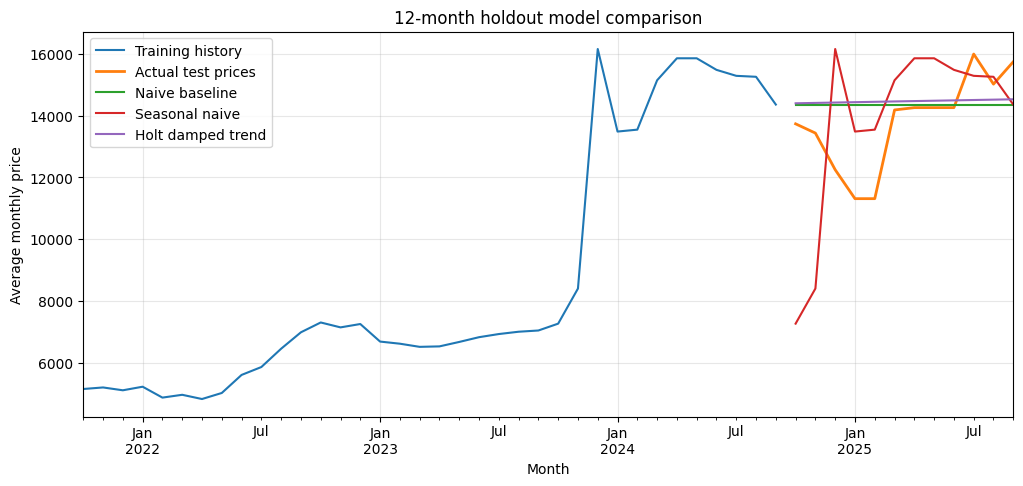

In [ ]:

# Chronological 12-month holdout evaluation
train = monthly.iloc[:-12]
test = monthly.iloc[-12:]

# Model 1: Naive baseline
baseline_pred = pd.Series(
    train.iloc[-1],
    index=test.index,
    name="Naive baseline"
)

# Model 2: Seasonal naive (same month from the previous year)
seasonal_naive_pred = pd.Series(
    train.iloc[-12:].to_numpy(),
    index=test.index,
    name="Seasonal naive"
)

# Model 3: Holt's damped-trend model
holt_fit = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
).fit(optimized=True)

holt_pred = holt_fit.forecast(12)

def evaluate(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = (
        np.abs((actual - predicted) / actual).mean() * 100
    )
    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

metrics = pd.DataFrame({
    "Naive baseline": evaluate(test, baseline_pred),
    "Seasonal naive": evaluate(test, seasonal_naive_pred),
    "Holt damped trend": evaluate(test, holt_pred)
}).T

display(metrics.round(2))

# Select the model with the lowest holdout MAE
predictions = {
    "Naive baseline": baseline_pred,
    "Seasonal naive": seasonal_naive_pred,
    "Holt damped trend": holt_pred
}

selected_model_name = metrics["MAE"].idxmin()

print("Selected model:", selected_model_name)
print("Selection criterion: lowest MAE on the chronological holdout")

# Plot actual and predicted values
fig, ax = plt.subplots(figsize=(12, 5))
train.tail(36).plot(ax=ax, label="Training history")
test.plot(ax=ax, label="Actual test prices", linewidth=2)

for name, pred in predictions.items():
    pred.plot(ax=ax, label=name)

ax.set_title("12-month holdout model comparison")
ax.set_xlabel("Month")
ax.set_ylabel("Average monthly price")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


### Interpretation of metrics
- **MAE** is the average absolute prediction error in the dataset's price units.
- **RMSE** penalizes larger errors more heavily.
- **MAPE** expresses absolute error as a percentage of actual values; it can be unstable when actual values are close to zero, though the supplied prices are positive.
- Lower values indicate better holdout performance. Do not interpret one split as proof that the model will perform equally well in future market conditions.

In [ ]:

# Rolling-origin backtesting: 12-month horizon
# Each test window occurs after its own training window.

def rolling_backtest(series, initial_train_size, horizon=12):
    records = []

    for origin in range(
        initial_train_size,
        len(series) - horizon + 1,
        horizon
    ):
        history = series.iloc[:origin]
        actual = series.iloc[origin:origin + horizon]

        forecasts = {
            "Naive baseline": pd.Series(
                history.iloc[-1],
                index=actual.index
            ),
            "Seasonal naive": pd.Series(
                history.iloc[-12:].to_numpy(),
                index=actual.index
            )
        }

        fitted = ExponentialSmoothing(
            history,
            trend="add",
            damped_trend=True,
            seasonal=None,
            initialization_method="estimated"
        ).fit(optimized=True)

        forecasts["Holt damped trend"] = fitted.forecast(horizon)

        for model_name, prediction in forecasts.items():
            records.append({
                "origin": history.index[-1].strftime("%Y-%m"),
                "model": model_name,
                "MAE": mean_absolute_error(actual, prediction),
                "RMSE": np.sqrt(
                    mean_squared_error(actual, prediction)
                ),
                "MAPE (%)": (
                    np.abs((actual - prediction) / actual).mean()
                    * 100
                )
            })

    return pd.DataFrame(records)

backtest_results = rolling_backtest(
    monthly,
    initial_train_size=len(monthly) - 60,
    horizon=12
)

display(backtest_results.round(2))

print("Average rolling-origin metrics:")
display(
    backtest_results.groupby("model")[
        ["MAE", "RMSE", "MAPE (%)"]
    ].mean().sort_values("MAE").round(2)
)

# Assess model stability: compare performance by backtest origin.
backtest_pivot = backtest_results.pivot(index="origin", columns="model", values="MAE")
print("MAE by rolling-origin window (lower is better):")
display(backtest_pivot.round(2))
naive_mean = backtest_results.loc[backtest_results.model == "Naive baseline", "MAE"].mean()
holt_mean = backtest_results.loc[backtest_results.model == "Holt damped trend", "MAE"].mean()
print(f"Mean rolling MAE difference (Holt - naive): {holt_mean - naive_mean:.2f} price units")
print("Small mean differences do not establish a reliable winner; inspect window-level variability.")


,origin,model,MAE,RMSE,MAPE (%)
0,2020-09,Naive baseline,2219.58,3282.15,42.57
1,2020-09,Seasonal naive,2074.58,3088.90,39.81
2,2020-09,Holt damped trend,2225.36,3313.12,42.87
3,2021-09,Naive baseline,718.42,967.48,12.13
4,2021-09,Seasonal naive,4230.00,4712.00,82.10
5,2021-09,Holt damped trend,709.37,958.54,11.97
6,2022-09,Naive baseline,245.83,286.87,3.63
7,2022-09,Seasonal naive,1439.58,1561.27,20.97
8,2022-09,Holt damped trend,254.44,298.55,3.76
9,2023-09,Naive baseline,6805.58,7367.09,45.81


Average rolling-origin metrics:


,MAE,RMSE,MAPE (%)
model,,,
Naive baseline,2229.95,2693.87,22.65
Holt damped trend,2232.43,2699.28,22.73
Seasonal naive,3403.90,3972.02,41.41


MAE by rolling-origin window (lower is better):


model,Holt damped trend,Naive baseline,Seasonal naive
origin,,,
2020-09,2225.36,2219.58,2074.58
2021-09,709.37,718.42,4230.00
2022-09,254.44,245.83,1439.58
2023-09,6785.78,6805.58,6978.92
2024-09,1187.20,1160.33,2296.42


Mean rolling MAE difference (Holt - naive): 2.48 price units
Small mean differences do not establish a reliable winner; inspect window-level variability.


## 6. Fit on all available data and forecast 12 months

Selected model: Naive baseline


,forecast_month,predicted_avg_monthly_price
0,2025-10,15750.0
1,2025-11,15750.0
2,2025-12,15750.0
3,2026-01,15750.0
4,2026-02,15750.0
5,2026-03,15750.0
6,2026-04,15750.0
7,2026-05,15750.0
8,2026-06,15750.0
9,2026-07,15750.0


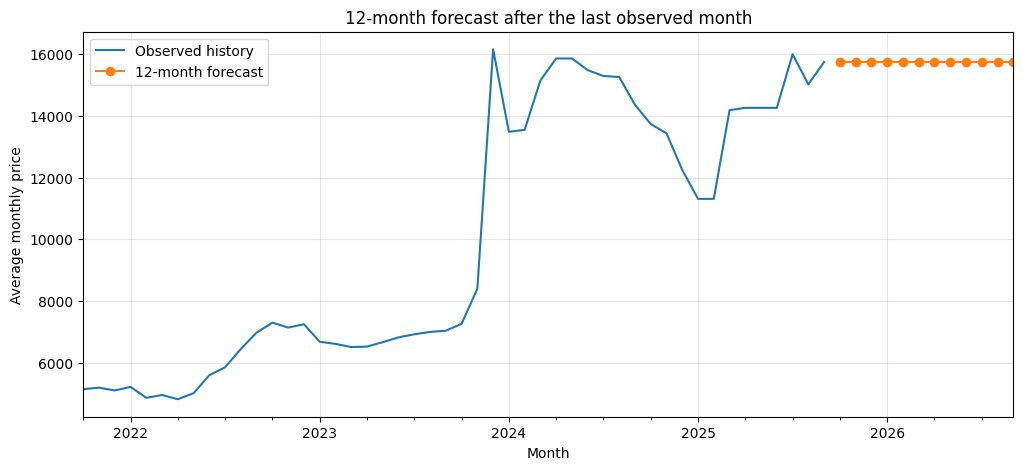

Saved forecast_results.csv (12 rows). Download it from Colab's Files sidebar.


In [ ]:

# Refit the selected model using all available observations

forecast_index = pd.date_range(
    start=monthly.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

if selected_model_name == "Naive baseline":
    forecast = pd.Series(
        monthly.iloc[-1],
        index=forecast_index
    )

elif selected_model_name == "Seasonal naive":
    forecast = pd.Series(
        monthly.iloc[-12:].to_numpy(),
        index=forecast_index
    )

elif selected_model_name == "Holt damped trend":
    final_fit = ExponentialSmoothing(
        monthly,
        trend="add",
        damped_trend=True,
        seasonal=None,
        initialization_method="estimated"
    ).fit(optimized=True)

    forecast = final_fit.forecast(12)

forecast = forecast.clip(lower=0)

forecast_table = pd.DataFrame({
    "forecast_month": forecast.index.strftime("%Y-%m"),
    "predicted_avg_monthly_price": forecast.values
})

print("Selected model:", selected_model_name)
display(forecast_table.round(2))

fig, ax = plt.subplots(figsize=(12, 5))
monthly.tail(48).plot(ax=ax, label="Observed history")
forecast.plot(ax=ax, label="12-month forecast", marker="o")

ax.set_title("12-month forecast after the last observed month")
ax.set_xlabel("Month")
ax.set_ylabel("Average monthly price")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

# Export the full forecast for the reviewer.
FORECAST_CSV = "forecast_results.csv"
forecast_table.to_csv(FORECAST_CSV, index=False)
print(f"Saved {FORECAST_CSV} (12 rows). Download it from Colab's Files sidebar.")


### Indicative forecast error bands (not calibrated prediction intervals)
The ranges below use the distribution of absolute errors from **non-overlapping historical 12-month naive forecasts**. They communicate historical error magnitude; they are **not** statistically calibrated 80% or 95% prediction intervals, do not capture model uncertainty rigorously, and may not cover future regime changes. The bounds are clipped at zero because prices cannot be negative. For a production system, use more backtest origins and horizon-specific conformal calibration or bootstrap intervals.

In [ ]:
# Empirical historical absolute errors by forecast horizon for the selected model.
# Backtest origins are spaced 12 months apart to avoid overlapping test windows.
error_rows = []
for origin in range(len(monthly) - 60, len(monthly) - 12 + 1, 12):
    history = monthly.iloc[:origin]
    actual = monthly.iloc[origin:origin + 12]
    if selected_model_name == "Naive baseline":
        pred = np.repeat(history.iloc[-1], 12)
    elif selected_model_name == "Seasonal naive":
        pred = history.iloc[-12:].to_numpy()
    else:
        fitted = ExponentialSmoothing(history, trend="add", damped_trend=True,
                                      seasonal=None, initialization_method="estimated").fit(optimized=True)
        pred = fitted.forecast(12).to_numpy()
    for h, (y, yhat) in enumerate(zip(actual.to_numpy(), pred), start=1):
        error_rows.append({"horizon": h, "absolute_error": abs(y - yhat)})
error_df = pd.DataFrame(error_rows)
# A common historical 90th-percentile error magnitude across all horizons.
# Small sample; descriptive scenario range only.
error_radius = float(error_df["absolute_error"].quantile(0.90))
forecast_table["indicative_lower"] = np.maximum(0, forecast_table["predicted_avg_monthly_price"] - error_radius)
forecast_table["indicative_upper"] = forecast_table["predicted_avg_monthly_price"] + error_radius
forecast_table.to_csv("forecast_results.csv", index=False)
print(f"Historical 90th-percentile absolute error: {error_radius:.2f} price units")
print("Indicative scenario range only; NOT a calibrated 90% prediction interval.")
display(forecast_table.round(2))


Historical 90th-percentile absolute error: 8121.30 price units
Indicative scenario range only; NOT a calibrated 90% prediction interval.


,forecast_month,predicted_avg_monthly_price,indicative_lower,indicative_upper
0,2025-10,15750.0,7628.7,23871.3
1,2025-11,15750.0,7628.7,23871.3
2,2025-12,15750.0,7628.7,23871.3
3,2026-01,15750.0,7628.7,23871.3
4,2026-02,15750.0,7628.7,23871.3
5,2026-03,15750.0,7628.7,23871.3
6,2026-04,15750.0,7628.7,23871.3
7,2026-05,15750.0,7628.7,23871.3
8,2026-06,15750.0,7628.7,23871.3
9,2026-07,15750.0,7628.7,23871.3


### Interpretation of the 12-month forecast

The forecasting models were evaluated using a chronological holdout period, with MAE, RMSE, and MAPE used to compare predictive accuracy. A naive baseline was included to establish a simple benchmark, alongside seasonal-naive and Holt's damped-trend exponential smoothing models.

The final model should be selected based on both holdout accuracy and rolling-origin backtesting results. If the naive baseline performs best, its forecast will remain constant at the latest observed price. This is a legitimate baseline prediction, but it does not capture future price fluctuations.

The supplied dataset ends in September 2025. Therefore, the forecast covers October 2025 to September 2026 and should not be interpreted as a current forecast for October 2026. Updated data and a new evaluation are required before using the results for current business decisions.

## 7. Business actions in response to predicted price changes

Actions should be proportional to forecast uncertainty and the business's actual exposure:
1. **Procurement and inventory:** If prices are expected to rise, assess whether phased early procurement or safety-stock adjustments are economical; avoid overstocking perishable goods.
2. **Supplier strategy:** Discuss forward contracts, alternate suppliers, and delivery windows when a sustained rise is forecast.
3. **Pricing and customer communication:** Review margin impact and consider transparent, staged price changes rather than reacting to a single monthly forecast.
4. **Risk scenarios:** Prepare base, upside and downside scenarios; define decision thresholds with finance and operations.
5. **Human review:** Validate forecasts against local market intelligence, seasonality, weather, policy changes, and supply disruptions before committing money.

The dataset has only date and average price; it does not identify the commodity, geography, costs, demand, or inventory. Therefore, these are general decision options, not commodity-specific recommendations.

## 8. How to measure whether actions worked

Before implementing an action, record a baseline and define the expected outcome. Compare an appropriate post-action period against the baseline and, where possible, a comparable untreated commodity/market or control group.

Suggested measures:
- Procurement cost per unit and gross margin.
- Stockout rate, spoilage/wastage, and inventory days.
- Forecast MAE/RMSE against actual prices after each month closes.
- Supplier lead time and price volatility.
- Customer retention or order fulfilment, if those outcomes are relevant.

Use a pre/post analysis and preferably a difference-in-differences or controlled pilot when a credible comparison group exists. Account for seasonality and other market changes; a simple before/after improvement does not prove the action caused the change.

## 9. Django production deployment

A practical Django design:
1. Package preprocessing and forecasting code in a versioned Python module; pin dependencies and save the trained model artifact.
2. Create a Django app with a `ForecastRun` model storing model version, training-data cutoff, creation time, forecast horizon, and results.
3. Expose authenticated endpoints such as `POST /api/forecasts/` and `GET /api/forecasts/{id}/`. Validate inputs with Django REST Framework serializers, enforce permissions, and log requests.
4. Run model inference in a service layer rather than inside views. For a small model, synchronous inference may be sufficient; use a background worker for expensive retraining or large batch jobs.
5. Containerize the application, use environment variables/secrets, deploy behind HTTPS, and configure database migrations, backups, structured logs, health checks and CI/CD.
6. Never train on future observations during evaluation. Store the dataset cutoff and model version for reproducibility.

## 10. Integrating Django, FastAPI, Next.js and React Native

**Recommended separation of responsibilities**
- **Django:** user/admin management, permissions, business records, audit history, and forecast request persistence.
- **FastAPI:** a lightweight inference API if model serving needs to scale independently. Load the versioned model at application startup and validate requests/responses with Pydantic.
- **Django ↔ FastAPI:** call over a private network with service authentication, timeouts, retries where safe, and clear error handling. Avoid exposing internal service credentials to clients.
- **Next.js:** call Django endpoints from server-side code or a controlled backend-for-frontend layer. Keep secrets on the server; handle loading, validation errors, and empty states.
- **React Native:** call the HTTPS API using a token-based auth flow; store tokens securely using platform-appropriate secure storage. Do not embed API secrets in the mobile app.
- **API contract:** document schemas with OpenAPI, version endpoints, validate inputs, rate-limit, and return consistent status codes.

For example, a forecast request could accept a commodity identifier and horizon only if those fields are available in a future, expanded dataset. The supplied dataset currently contains only `date` and `avg_monthly_price`.

## 11. Production monitoring, drift and retraining

Monitor:
- **Service health:** latency, throughput, error rate, availability and resource usage.
- **Data quality:** missing months, duplicate dates, invalid/non-positive prices, unexpected units, and delayed ingestion.
- **Model quality:** once actual prices arrive, compute MAE/RMSE/MAPE by month and compare against the naive baseline.
- **Drift:** track changes in price level, volatility, and residual distributions. A univariate series cannot support feature drift checks for variables that do not exist in the dataset.
- **Retraining:** retrain on a schedule or when pre-agreed error/drift thresholds are crossed, then evaluate the new model against the current production model using rolling-origin backtests.
- **Governance:** version data, code, model artifacts and metrics; retain audit logs; provide rollback and human override mechanisms.

Do not automatically promote a retrained model without validation. Set thresholds based on business cost and historical backtesting rather than choosing arbitrary values.

## 12. Limitations and next steps
- The supplied CSV ends at September 2025; refresh it before using forecasts for current decisions.
- The data dictionary defines only `date` and `avg_monthly_price`; commodity identity and market context are not provided here.
- One 12-month holdout gives a limited estimate of generalization. Add rolling-origin backtesting and compare with seasonal-naive, ETS variants, and other models before production.
- Indicative historical-error bands are shown, but they are not calibrated prediction intervals. For business decisions, estimate forecast uncertainty and communicate it alongside point forecasts.
- Confirm the final forecast and metrics by running the notebook in the same environment where it will be submitted.
- Rolling-origin backtesting was performed across multiple historical forecast windows. Further evaluation using additional forecasting methods and updated data would help assess model robustness before production deployment.